# Store Sales Forecasting for Corporación Favorita

UW ECON 481A · Autumn 2026

**Research question.** Given 16 days of scheduled promotions, does a frozen
time-series foundation model forecast grocery sales more accurately than
a model fitted to Favorita's own data? How much of the improvement comes
from the future promotion counts?

Replenishment planners must forecast demand before stock arrives. The
observed target is daily unit sales for a store and product family. Sales
may be constrained by inventory. Forecast accuracy measures how well a
model predicts recorded sales. [Competition data](https://www.kaggle.com/c/store-sales-time-series-forecasting/data)

## Reproduce the results

The notebook reads one run bundle containing its manifest, overall scores,
subgroup scores, and tuning results. The default is the archived run in
`files/final-results`. Set `ECON481_RESULTS` to the output directory of a
fresh benchmark to render that run. The fixture verifies the report using
generated data when the archived run is unavailable.

GitHub Actions can execute this report from the saved aggregates. Model
fitting and pretrained inference use the separate benchmark command and
official competition data. See the setup and full run commands in the
[README](README.md) and the [experiment plan](files/experiment-plan.md).

In [1]:
import json
import os
import subprocess
import sys
from hashlib import sha256
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

archived_results = Path("files/final-results")
override = os.environ.get("ECON481_RESULTS")
results = Path(override) if override else archived_results
if not override and not (results / "manifest.json").is_file():
    results = Path("results/final-fixture")
    subprocess.run(
        [
            sys.executable,
            "-m",
            "auxiliary.final_experiment",
            "--fixture",
            "--output-dir",
            str(results),
        ],
        check=True,
    )

manifest = json.loads((results / "manifest.json").read_text(encoding="utf-8"))


def read_artifact(artifact, **options):
    content = (results / artifact).read_bytes()
    if sha256(content).hexdigest() != manifest["artifact_sha256"][artifact]:
        raise ValueError(f"{artifact} does not match its manifest hash.")
    return pd.read_csv(BytesIO(content), **options)


scores = read_artifact("scores.csv")
slices = read_artifact("slices.csv", dtype={"group": str})
tuning = read_artifact("tuning.csv")

fixture = manifest["synthetic"]
source = "Generated fixture" if fixture else "Official Kaggle Store Sales data"
display(Markdown(f"**Data source:** {source}  \n**Results bundle:** `{results}`"))
if fixture:
    display(Markdown("Fixture scores verify the workflow using simulated data."))
elif not manifest["complete_model_set"]:
    display(Markdown("This official-data run uses a partial set of models."))

labels = {
    "seasonal_naive": "Seasonal naïve",
    "weekday_mean": "Eight-week weekday mean",
    "prophet_promotion": "Prophet + promotions",
    "t0_beta_promotion": "t0-beta + promotions",
    "global_hgb_sales": "HGB · sales + calendar",
    "global_hgb_historical_promotion": "HGB · past promotions",
    "global_hgb_future_promotion": "HGB · past + scheduled promotions",
}
colors = {
    "seasonal_naive": "#7e8583",
    "weekday_mean": "#7e8583",
    "prophet_promotion": "#a15b30",
    "t0_beta_promotion": "#1e7059",
    "global_hgb_sales": "#7b9fb8",
    "global_hgb_historical_promotion": "#517fa8",
    "global_hgb_future_promotion": "#294d85",
}
date_columns = ["fold", "role", "train_end", "forecast_start", "forecast_end"]
windows = (
    scores[[*date_columns, "n"]]
    .drop_duplicates()
    .sort_values("forecast_start")
    .reset_index(drop=True)
)
expected_windows = (
    pd.DataFrame(manifest["folds"])[date_columns]
    .sort_values("forecast_start")
    .reset_index(drop=True)
)
expected_pairs = {
    (fold["fold"], model) for fold in manifest["folds"] for model in manifest["models"]
}
observed_pairs = set(zip(scores["fold"], scores["model"]))
if (
    not windows[date_columns].equals(expected_windows)
    or len(scores) != len(expected_pairs)
    or observed_pairs != expected_pairs
):
    raise ValueError(
        "Scores must match all manifest models, forecast dates, and windows."
    )
fold_dates = windows.set_index("fold")["forecast_start"].to_dict()

Matplotlib is building the font cache; this may take a moment.


**Data source:** Official Kaggle Store Sales data  
**Results bundle:** `files/final-results`

## Forecast design

Kaggle asks for daily unit sales forecasts over August 16–31, 2017. The
labeled panel has 54 stores, 33 product families, and 3,000,888 rows. Four
December 25 dates are absent from the file and stay missing on the daily
calendar. A recorded zero remains an observed sale value.

The benchmark simulates forecasts at multiple historical cutoffs. Every
model predicts the complete horizon from the same origin and is scored on
the same rows. Models use up to 512 calendar days of sales at that origin.
Development windows are used to choose configurations and the model for
the submission. A separate set of evaluation windows measures how that
choice performs on later dates. Development includes August 16–31, 2016,
which matches the calendar dates of the 2017 Kaggle test. The previous
June–August 2017 experiments informed the choice to test pooled models.
Their scores are preserved in the [previous comparison](files/global-model-comparison.md).

Future promotion counts are supplied in the Kaggle test file. Historical
backtests treat the recorded future counts as a plan known at the origin.
The files lack timestamped versions of promotion plans. Transactions and
realized oil prices from the forecast window are excluded.
[Kaggle overview](https://www.kaggle.com/c/store-sales-time-series-forecasting)

In [2]:
promoted_rows = slices.loc[
    slices["model"].eq("seasonal_naive")
    & slices["dimension"].eq("promotion")
    & slices["group"].eq("promotion")
].set_index("fold")["n"]
promoted_share = 100 * windows["fold"].map(promoted_rows).fillna(0) / windows["n"]
display(
    windows.assign(**{"Scheduled promotion rows (%)": promoted_share.round(1)})
    .rename(
        columns={
            "fold": "Window",
            "role": "Role",
            "train_end": "Sales through",
            "forecast_start": "First forecast date",
            "forecast_end": "Last forecast date",
            "n": "Scoring rows per model",
        }
    )
    .reset_index(drop=True)
)

,Window,Role,Sales through,First forecast date,Last forecast date,Scoring rows per model,Scheduled promotion rows (%)
0,development_1,development,2016-06-30,2016-07-01,2016-07-16,28512,41.1
1,development_2,development,2016-08-15,2016-08-16,2016-08-31,28512,36.0
2,development_3,development,2016-10-31,2016-11-01,2016-11-16,28512,44.1
3,development_4,development,2016-12-08,2016-12-09,2016-12-24,28512,48.2
4,development_5,development,2017-02-28,2017-03-01,2017-03-16,28512,43.0
5,development_6,development,2017-03-31,2017-04-01,2017-04-16,28512,42.8
6,evaluation_1,evaluation,2017-04-30,2017-05-01,2017-05-16,28512,50.0
7,evaluation_2,evaluation,2017-05-16,2017-05-17,2017-06-01,28512,47.4
8,evaluation_3,evaluation,2017-06-12,2017-06-13,2017-06-28,28512,45.1


## Models and scoring

The full benchmark compares these forecasting methods.

| Model | Forecast method |
| --- | --- |
| Seasonal naïve | Repeat the last observed sale for each weekday. |
| Eight-week weekday mean | Average recent same-weekday observations on the log-sales scale. |
| Prophet with promotions | Fit weekly and annual seasonality, a trend, and a promotion regressor by store and family where historical promotion counts vary. |
| t0-beta with promotions | Use a pinned pretrained transformer with sales history and known future covariates. The point forecast is its median on the log-sales scale. |
| Pooled histogram gradient boosting (HGB) | Train across all stores and families using past sales, store and product identifiers, calendar variables, and forecast lead. The ablation adds historical promotion summaries, then scheduled forecast-period counts. |

Each fitted model works on log-transformed sales and returns nonnegative
unit predictions. For pooled HGB, each training example simulates a past
forecast origin. Its features use information at that origin, and its label
must be observed by the evaluation cutoff.

Kaggle grades each store–family–day equally using the root mean squared
logarithmic error (RMSLE). Pool the squared log errors across rows before
taking their square root. MAE gives the mean absolute error in sales
units. WAPE gives the ratio of total absolute error to observed sales.

$$\mathrm{RMSLE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}
\left[\log(1+\widehat y_i)-\log(1+y_i)\right]^2}.$$

The t0 developers report excluding fev-bench datasets from t0-beta
pretraining. The fev-bench list includes Favorita. This check uses the
model developers' disclosures. A complete auditable pretraining corpus was
unavailable. [Prophet paper](https://doi.org/10.1080/00031305.2017.1380080) ·
[t0 technical report, §5.1.2](https://arxiv.org/pdf/2609.24559) ·
[fev-bench datasets](https://arxiv.org/html/2509.26468v1#A5)

In [3]:
def pooled_rmsle(frame, groups):
    losses = frame.assign(squared_log_error=frame["n"] * frame["rmsle"].pow(2))
    totals = losses.groupby(groups, observed=True)[["n", "squared_log_error"]].sum()
    return (totals["squared_log_error"] / totals["n"]).pow(0.5)


def show_chart(ax, description):
    figure = ax.figure
    figure.tight_layout()
    with BytesIO() as png:
        figure.savefig(png, format="png", dpi=125)
        display(Image(data=png.getvalue(), metadata={"alt": description}))
    plt.close(figure)


development = scores.loc[scores["role"].eq("development")]
evaluation = scores.loc[scores["role"].eq("evaluation")]
selected_model = manifest["selected_model"]
development_rmsle = pooled_rmsle(development, "model").sort_values()
evaluation_rmsle = pooled_rmsle(evaluation, "model").sort_values()

tuned = pooled_rmsle(tuning, "configuration").sort_values()
settings = pd.DataFrame.from_dict(manifest["hgb_configurations"], orient="index")[
    ["max_leaf_nodes", "l2_regularization"]
]
display(
    Markdown(
        f"**HGB configuration selected on development data:** "
        f"{manifest['selected_hgb_configuration']}.  \n"
        f"**Model selected on development data:** {labels.get(selected_model, selected_model)}."
    )
)
display(tuned.to_frame("Pooled tuning RMSLE").join(settings).round(5))

**HGB configuration selected on development data:** reference.  
**Model selected on development data:** HGB · past + scheduled promotions.

,Pooled tuning RMSLE,max_leaf_nodes,l2_regularization
configuration,,,
reference,0.52069,43,1.0
flexible,0.52086,63,0.5
regularized,0.52324,31,3.0


## Forecast accuracy across windows

Compare pooled development and evaluation errors, then inspect each
evaluation window. The evaluation dates reveal whether the choice made
during development transfers to later periods.

,Development RMSLE,Evaluation RMSLE,Evaluation MAE
model,,,
HGB · past + scheduled promotions,0.52069,0.41636,71.06389
HGB · sales + calendar,0.53746,0.42524,71.25887
t0-beta + promotions,0.52523,0.42565,66.59322
HGB · past promotions,0.53844,0.42662,71.76882
Prophet + promotions,0.67694,0.50242,128.24095
Seasonal naïve,0.67618,0.56105,87.67657
Eight-week weekday mean,0.64981,0.59415,78.41985


**Lowest pooled evaluation RMSLE:** HGB · past + scheduled promotions at 0.41636, 25.8% below seasonal naïve. The model selected in development scored 0.41636 on the same windows.

**Lowest pooled MAE:** t0-beta + promotions at 66.59 sales units per daily forecast.

fold,2017-05-01,2017-05-17,2017-06-13
model,,,
HGB · past + scheduled promotions,0.45331,0.40928,0.38350
HGB · sales + calendar,0.45941,0.42056,0.39315
t0-beta + promotions,0.46229,0.42118,0.39043
HGB · past promotions,0.46178,0.42190,0.39341
Prophet + promotions,0.56292,0.49085,0.44663
Seasonal naïve,0.57857,0.57926,0.52350
Eight-week weekday mean,0.71899,0.58877,0.44209


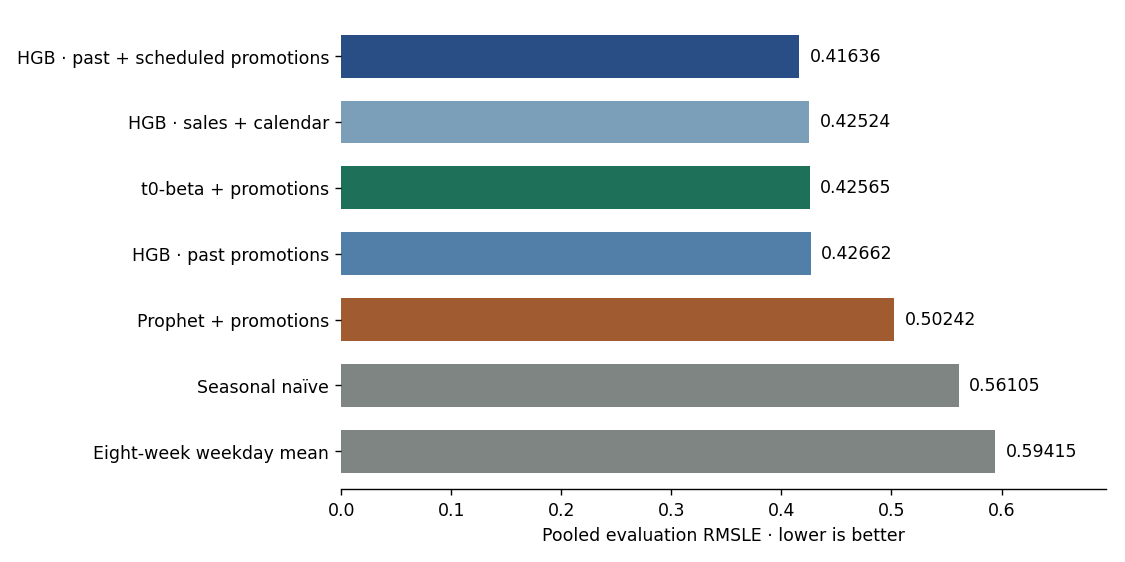

In [4]:
evaluation_mae = (
    evaluation.assign(total_abs_error=evaluation["n"] * evaluation["mae"])
    .groupby("model")[["n", "total_abs_error"]]
    .sum()
)
ranking = pd.DataFrame(
    {
        "Development RMSLE": development_rmsle,
        "Evaluation RMSLE": evaluation_rmsle,
        "Evaluation MAE": evaluation_mae["total_abs_error"] / evaluation_mae["n"],
    }
).sort_values("Evaluation RMSLE")
display(ranking.rename(index=labels).round(5))

first = evaluation_rmsle.index[0]
reference = evaluation_rmsle.get("seasonal_naive")
baseline_comparison = ""
if reference:
    reduction = 100 * (1 - evaluation_rmsle.iloc[0] / reference)
    baseline_comparison = f", {reduction:.1f}% below seasonal naïve"
display(
    Markdown(
        f"**Lowest pooled evaluation RMSLE:** {labels.get(first, first)} at "
        f"{evaluation_rmsle.iloc[0]:.5f}{baseline_comparison}. "
        f"The model selected in development scored "
        f"{evaluation_rmsle.loc[selected_model]:.5f} on the same windows."
    )
)
lowest_mae = ranking["Evaluation MAE"].idxmin()
if lowest_mae != first:
    display(
        Markdown(
            f"**Lowest pooled MAE:** {labels.get(lowest_mae, lowest_mae)} at "
            f"{ranking.loc[lowest_mae, 'Evaluation MAE']:.2f} sales units per daily forecast."
        )
    )

evaluation_folds = windows.loc[windows["role"].eq("evaluation"), "fold"]
fold_scores = evaluation.pivot(index="model", columns="fold", values="rmsle")
fold_scores = fold_scores.reindex(index=ranking.index, columns=evaluation_folds)
display(fold_scores.rename(index=labels, columns=fold_dates).round(5))

ax = (
    ranking["Evaluation RMSLE"]
    .rename(index=labels)
    .plot.barh(
        figsize=(9, 4.5),
        color=[colors.get(model, "#7e8583") for model in ranking.index],
        width=0.65,
    )
)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.5f", padding=6)
ax.set(
    xlabel="Pooled evaluation RMSLE · lower is better",
    ylabel="",
    xlim=(0, 1.17 * ranking["Evaluation RMSLE"].max()),
)
ax.spines[["top", "right", "left"]].set_visible(False)
show_chart(
    ax, "Horizontal bars rank models by pooled evaluation RMSLE, as in the table above."
)

In [5]:
# Compare the foundation model to the strongest scheduled-promotion HGB
# configuration chosen by development scores.
hgb = "global_hgb_future_promotion"
foundation = "t0_beta_promotion"
if {foundation, hgb}.issubset(fold_scores.index):
    paired = fold_scores.loc[[hgb, foundation]].T
    paired["t0-beta − HGB (RMSLE)"] = paired[foundation] - paired[hgb]
    display(paired.rename(index=fold_dates, columns=labels).round(5))
    gap = evaluation_rmsle.loc[foundation] - evaluation_rmsle.loc[hgb]
    hgb_wins = paired["t0-beta − HGB (RMSLE)"].gt(0).sum()
    display(
        Markdown(
            f"Across the evaluation windows, t0-beta minus HGB was **{gap:+.5f} RMSLE** "
            f"pooled. HGB had the lower error in **{hgb_wins} of {len(paired)}** windows. "
            "The windows share stores and families, so the paired differences "
            "describe sensitivity to forecast dates."
        )
    )

model,HGB · past + scheduled promotions,t0-beta + promotions,t0-beta − HGB (RMSLE)
fold,,,
2017-05-01,0.45331,0.46229,0.00898
2017-05-17,0.40928,0.42118,0.01190
2017-06-13,0.38350,0.39043,0.00693


Across the evaluation windows, t0-beta minus HGB was **+0.00929 RMSLE** pooled. HGB had the lower error in **3 of 3** windows. The windows share stores and families, so the paired differences describe sensitivity to forecast dates.

## What promotion information adds

The three HGB variants use the same tuned settings and benchmark dates.
Start with historical sales, add past
promotions, and then add scheduled future counts. The resulting error
differences measure predictive value under the schedule assumption.

In [6]:
hgb_steps = [
    "global_hgb_sales",
    "global_hgb_historical_promotion",
    "global_hgb_future_promotion",
]
display(ranking.reindex(hgb_steps).rename(index=labels).round(5))

finalists = [
    model
    for model in ("prophet_promotion", foundation, *hgb_steps)
    if model in evaluation_rmsle.index
]
groups = slices.loc[slices["role"].eq("evaluation") & slices["model"].isin(finalists)]
promo = groups.loc[groups["dimension"].eq("promotion")]
promo_scores = pooled_rmsle(promo, ["model", "group"]).unstack()
display(
    promo_scores.reindex(finalists)
    .rename(
        index=labels, columns={"promotion": "Promoted", "no_promotion": "Unpromoted"}
    )
    .round(5)
)

if {hgb_steps[1], hgb_steps[2]}.issubset(evaluation_rmsle.index):
    historical = evaluation_rmsle.loc[hgb_steps[1]]
    scheduled = evaluation_rmsle.loc[hgb_steps[2]]
    display(
        Markdown(
            f"Adding the future schedule to HGB with past promotions changed pooled "
            f"evaluation RMSLE by **{scheduled - historical:+.5f}** "
            f"({historical:.5f} to {scheduled:.5f})."
        )
    )

,Development RMSLE,Evaluation RMSLE,Evaluation MAE
model,,,
HGB · sales + calendar,0.53746,0.42524,71.25887
HGB · past promotions,0.53844,0.42662,71.76882
HGB · past + scheduled promotions,0.52069,0.41636,71.06389


group,Unpromoted,Promoted
model,,
Prophet + promotions,0.53052,0.46944
t0-beta + promotions,0.49621,0.33067
HGB · sales + calendar,0.48004,0.35503
HGB · past promotions,0.48052,0.35778
HGB · past + scheduled promotions,0.47966,0.33274


Adding the future schedule to HGB with past promotions changed pooled evaluation RMSLE by **-0.01026** (0.42662 to 0.41636).

## Forecast lead and sales sparsity

The lead-time profile uses the same models and evaluation dates to show
performance over the 16-day replenishment horizon. The sparsity groups
use each series' share of zero sales in the 56 days through the cutoff.
Low means up to 10%, middle means over 10% through 50%, and high means
over 50%.

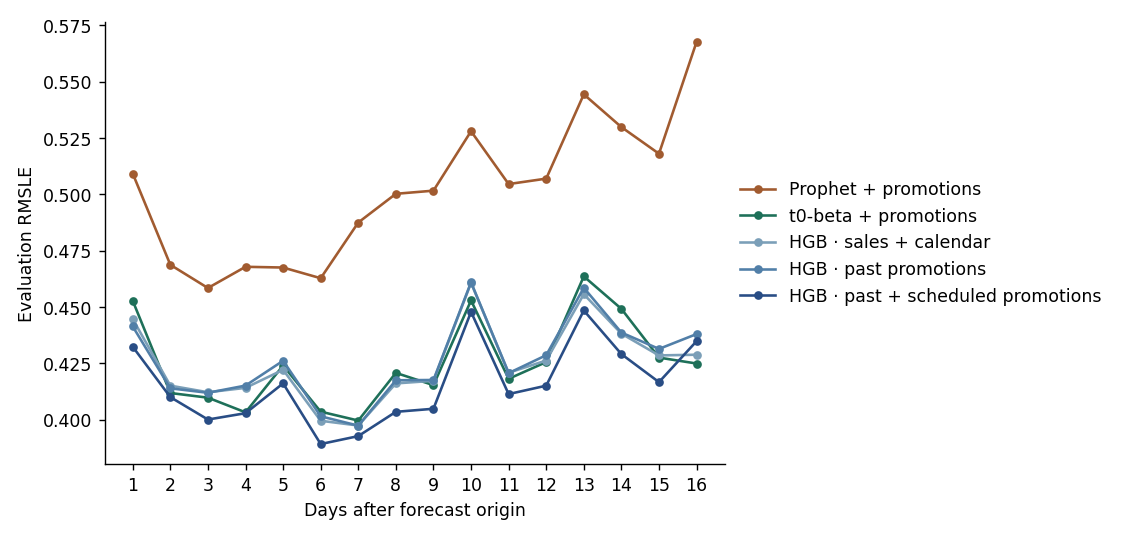

group,Low,Middle,High
model,,,
Prophet + promotions,0.44888,0.66082,0.64226
t0-beta + promotions,0.38996,0.63892,0.42884
HGB · sales + calendar,0.39550,0.65042,0.38127
HGB · past promotions,0.39597,0.65123,0.38890
HGB · past + scheduled promotions,0.38900,0.62390,0.37862


In [7]:
lead = groups.loc[groups["dimension"].eq("horizon_day")].copy()
lead["lead"] = lead["group"].astype(int)
lead_scores = pooled_rmsle(lead, ["lead", "model"]).unstack()
ax = (
    lead_scores.reindex(columns=finalists)
    .rename(columns=labels)
    .plot(
        marker="o",
        figsize=(9, 4.3),
        linewidth=1.5,
        markersize=4,
        color=[colors.get(model, "#7e8583") for model in finalists],
    )
)
ax.set(
    xlabel="Days after forecast origin",
    ylabel="Evaluation RMSLE",
    xticks=lead_scores.index,
)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
show_chart(
    ax, "Lines show evaluation RMSLE from days 1 through 16 for the comparison models."
)

sparse = groups.loc[groups["dimension"].eq("recent_zero_rate")]
sparse_scores = pooled_rmsle(sparse, ["model", "group"]).unstack()
if not sparse_scores.empty:
    display(
        sparse_scores.reindex(index=finalists, columns=["low", "middle", "high"])
        .rename(index=labels, columns=str.title)
        .round(5)
    )

## Replenishment and directional errors

The 16-day diagnostics sum daily sales and forecasts within each
store–family. Across the panel, shortfalls and excesses are totaled
separately. This preserves their direction across series. WAPE uses daily
absolute error, so it also reflects errors that cancel within a series
over the 16-day period.

To show how priorities affect the comparison, assign one cost unit to
each excess unit and weight each shortfall by $r$. The sensitivity check
compares $r \times \mathrm{shortfall} + \mathrm{excess}$ at shortfall-to-excess
cost ratios of 0.5:1, 1:1, and 2:1. These ratios are hypothetical. The
inputs are directional sales forecast errors.

In [8]:
under = "horizon_underforecast_units"
over = "horizon_overforecast_units"
directional = evaluation.loc[evaluation["model"].isin(finalists)].copy()
directional["WAPE (%)"] = 100 * directional["wape"]
directional["Net overforecast units"] = directional[over] - directional[under]
display(
    directional.set_index(["fold", "model"])[
        ["WAPE (%)", under, over, "Net overforecast units"]
    ]
    .round({"WAPE (%)": 2, under: 0, over: 0, "Net overforecast units": 0})
    .rename(
        index={**fold_dates, **labels},
        columns={
            under: "Underforecast units",
            over: "Overforecast units",
        },
    )
)

variants = directional.loc[directional["model"].isin(hgb_steps[1:])]
if variants["model"].nunique() == 2:
    by_fold = variants.pivot(index="fold", columns="model", values=[under, over])
    delta = by_fold.xs(hgb_steps[2], level="model", axis=1) - by_fold.xs(
        hgb_steps[1], level="model", axis=1
    )
    display(Markdown("**Change after giving HGB the future schedule**"))
    display(
        delta.rename(
            index=fold_dates,
            columns={
                under: "Change in underforecast units",
                over: "Change in overforecast units",
            },
        ).round(0)
    )

    cost_delta = pd.DataFrame(
        {f"{weight:g}:1": weight * delta[under] + delta[over] for weight in (0.5, 1, 2)}
    )
    schedule_wins = cost_delta.lt(0).sum()
    display(
        Markdown(
            "**Change in hypothetical cost with the schedule**  \n"
            "Negative values favor using the schedule."
        )
    )
    display(cost_delta.rename(index=fold_dates).round(0))
    win_summary = ", ".join(
        f"{ratio}: {wins} of {len(delta)}" for ratio, wins in schedule_wins.items()
    )
    display(
        Markdown(f"**Windows favoring the schedule by cost ratio.** {win_summary}.")
    )

WAPE (%)  Underforecast units  \
fold       model                                                              
2017-05-01 Prophet + promotions                  23.23            1469519.0   
           t0-beta + promotions                  16.34            1181944.0   
           HGB · sales + calendar                17.61            1193833.0   
           HGB · past promotions                 17.68            1226292.0   
           HGB · past + scheduled promotions     17.38            1176739.0   
2017-05-17 Prophet + promotions                  30.47            1735624.0   
           t0-beta + promotions                  13.34             557738.0   
           HGB · sales + calendar                14.27             674939.0   
           HGB · past promotions                 14.47             661316.0   
           HGB · past + scheduled promotions     14.56             705301.0   
2017-06-13 Prophet + promotions                  27.39             407796.0   
           t0-beta + promotions                  12.13             262818.0   
           HGB · sales + calendar                12.84             399154.0   
           HGB · past promotions                 12.89             391739.0   
           HGB · past + scheduled promotions     12.66             356053.0   

                                              Overforecast units  \
fold       model                                                   
2017-05-01 Prophet + promotions                         508473.0   
           t0-beta + promotions                          88679.0   
           HGB · sales + calendar                       204918.0   
           HGB · past promotions                        197750.0   
           HGB · past + scheduled promotions            211473.0   
2017-05-17 Prophet + promotions                        1616792.0   
           t0-beta + promotions                         188721.0   
           HGB · sales + calendar                       183438.0   
           HGB · past promotions                        190354.0   
           HGB · past + scheduled promotions            172191.0   
2017-06-13 Prophet + promotions                        2330990.0   
           t0-beta + promotions                         479483.0   
           HGB · sales + calendar                       366988.0   
           HGB · past promotions                        379537.0   
           HGB · past + scheduled promotions            387879.0   

                                              Net overforecast units  
fold       model                                                      
2017-05-01 Prophet + promotions                            -961046.0  
           t0-beta + promotions                           -1093265.0  
           HGB · sales + calendar                          -988916.0  
           HGB · past promotions                          -1028542.0  
           HGB · past + scheduled promotions               -965266.0  
2017-05-17 Prophet + promotions                            -118832.0  
           t0-beta + promotions                            -369017.0  
           HGB · sales + calendar                          -491500.0  
           HGB · past promotions                           -470962.0  
           HGB · past + scheduled promotions               -533111.0  
2017-06-13 Prophet + promotions                            1923194.0  
           t0-beta + promotions                             216664.0  
           HGB · sales + calendar                           -32166.0  
           HGB · past promotions                            -12202.0  
           HGB · past + scheduled promotions                 31827.0

**Change after giving HGB the future schedule**

,Change in underforecast units,Change in overforecast units
fold,,
2017-05-01,-49553.0,13723.0
2017-05-17,43986.0,-18163.0
2017-06-13,-35686.0,8342.0


**Change in hypothetical cost with the schedule**  
Negative values favor using the schedule.

,0.5:1,1:1,2:1
fold,,,
2017-05-01,-11053.0,-35829.0,-85382.0
2017-05-17,3829.0,25822.0,69808.0
2017-06-13,-9501.0,-27344.0,-63030.0


**Windows favoring the schedule by cost ratio.** 0.5:1: 2 of 3, 1:1: 2 of 3, 2:1: 2 of 3.

## Decision Loop

| Stage | Application at Favorita |
| --- | --- |
| Learn | Timestamp promotion plans at each forecast origin and compare the incumbent process, pooled HGB, and t0-beta on the same windows. |
| Decide | Pilot forecasts alongside the current ordering process. Measure both sides of the unit error and record on-shelf availability, waste, and lead times. Evaluate priorities using the store's stockout and holding costs. |
| Repeat | Review model rankings on new forecast windows and monitor where promotion plans, forecast leads, or product mix change the error. |

The diagnostics describe sales forecast errors at one retailer. Inventory,
orders, carrying costs, and lost sales are needed to quantify the effects
on stockouts, waste, and profit. An evaluation of the ordering policy
also needs a design that can isolate its effects.
[Course Decision Loop](https://eisenhauerio.github.io/courses-business-decisions/decision-loop/index.html)

This notebook reports scores from the labeled historical evaluation. An
official Kaggle leaderboard score is pending.
[Competition overview](https://www.kaggle.com/c/store-sales-time-series-forecasting)